In [2]:
%pip install statsmodels

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.7/11.7 MB 18.1 MB/s eta 0:00:00m eta 0:00:010:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.1/25.1 MB 19.0 MB/s eta 0:00:00m eta 0:00:010:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 118.9/118.9 KB 4.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 233.3/233.3 KB 9.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 501.7/501.7 KB 13.4 MB/s eta 0:00:000:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 105.4/105.4 KB 3.9 MB/s eta 0:00:00
You should consider upgrading via the '/Users/diegoxoyonlorenzana/MisProyectos/jupyter-env/bin/python -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


TOTAL               mean       mean_se  mean_ci_lower  mean_ci_upper
Fecha                                                               
2026-09-01  8.746083e+09  4.523300e+08   7.859532e+09   9.632633e+09
2026-10-01  1.456566e+10  4.550293e+08   1.367382e+10   1.545750e+10
2026-11-01  8.605963e+09  4.604566e+08   7.703484e+09   9.508441e+09
2026-12-01  9.537602e+09  4.623504e+08   8.631412e+09   1.044379e+10
2027-01-01  1.206978e+10  4.649041e+08   1.115858e+10   1.298097e+10
2027-02-01  8.969961e+09  4.672761e+08   8.054117e+09   9.885805e+09
2027-03-01  1.227635e+10  4.696755e+08   1.135581e+10   1.319690e+10
2027-04-01  1.426916e+10  4.720532e+08   1.334396e+10   1.519437e+10
2027-05-01  9.543288e+09  4.744213e+08   8.613440e+09   1.047314e+10
2027-06-01  9.825274e+09  4.767771e+08   8.890808e+09   1.075974e+10
2027-07-01  1.637039e+10  4.791215e+08   1.543133e+10   1.730945e+10
2027-08-01  9.574460e+09  4.814544e+08   8.630827e+09   1.051809e+10
2027-09-01  9.695722e+09  7.939860

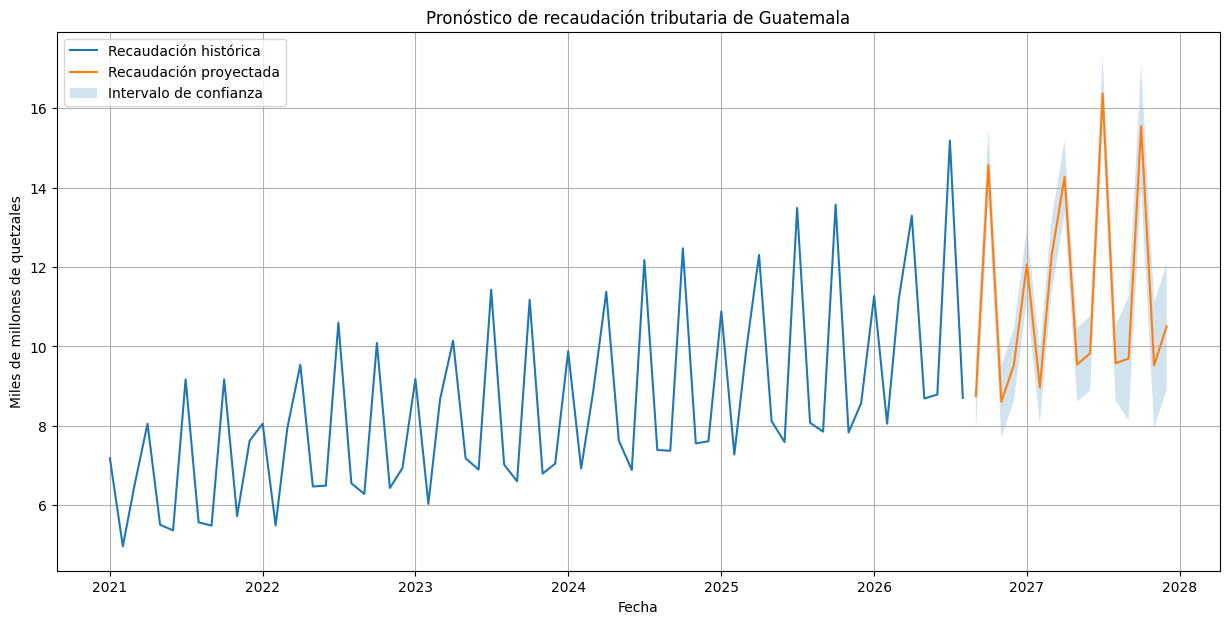

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from statsmodels.tsa.statespace.sarimax import SARIMAX

# 1. Cargar archivo
df = pd.read_csv("sat21-26.csv")

# 2. Preparar fechas
df["fecha"] = pd.to_datetime(df["fecha"])

# 3. Construir serie nacional
serie = (
    df.groupby("fecha")["TOTAL"]
    .sum()
    .sort_index()
    .asfreq("MS")
)

# 4. Entrenar modelo
modelo = SARIMAX(
    serie,
    order=(1, 1, 1),
    seasonal_order=(1, 1, 0, 12),
    enforce_stationarity=False,
    enforce_invertibility=False
)

resultado = modelo.fit(disp=False)

# 5. Pronosticar 16 meses
pronostico = resultado.get_forecast(steps=16)

# 6. Obtener resultados
tabla = pronostico.summary_frame()

tabla.index.name = "Fecha"

print(tabla)

# 7. Graficar
plt.figure(figsize=(15, 7))

plt.plot(
    serie.index,
    serie.values / 1e9,
    label="Recaudación histórica"
)

plt.plot(
    tabla.index,
    tabla["mean"] / 1e9,
    label="Recaudación proyectada"
)

plt.fill_between(
    tabla.index,
    tabla["mean_ci_lower"] / 1e9,
    tabla["mean_ci_upper"] / 1e9,
    alpha=0.2,
    label="Intervalo de confianza"
)

plt.title("Pronóstico de recaudación tributaria de Guatemala")
plt.xlabel("Fecha")
plt.ylabel("Miles de millones de quetzales")
plt.legend()
plt.grid(True)
plt.show()